![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Build the Core

*Project 3 — AI Product: From Model to Product*

**Team:** Theophilus Kobina Sarpey
**Track:** both — model track (voltage models, failure screening, comment NLP) and LLM track (RAG, agent, report)
**Data:** ECSIM PEM fuel-cell dataset (Hamidi, Haghighi, Askari 2020, doi:10.26434/chemrxiv.11902023, CC BY 4.0) + 30 curated knowledge notes (`data/knowledge/`)

---

Build the DFT track (limiting potential, ASE workflow, ML screening with uncertainty, stability flags, next calculation), the device layer (physics, voltage models, comment classifiers) and the LLM track (retrieval, grounded answers, agent, report), compare the design choices with evidence, and save the final versions.

> **Done when:** you have an end-to-end result on both tracks that beats (or honestly fails to beat) the baselines, one design choice is compared with evidence, and you can say why you chose the final versions. The test files and the evaluation outcome are **not** looked at here; notebook 03 does that once.

---
## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path
# Run from the project root or from notebooks/: find the folder that contains src/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FIG_DIR, MODELS_DIR, REPORTS_DIR, SEED, ensure_dirs
ensure_dirs()
from src.functions import *          # template convention: reusable logic lives in src/
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

def savefig(name):
    """Save the current figure into reports/figures/ for the README and slides."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=130)

## Live or offline? (set this once)

The next cell is the **connection panel**. Set `USE_LIVE`, and either keep your key in `.env` (`OPEN_AI_KEY`, `OPEN_AI_MODEL=GPT-6-LUNA`) or set `ASK_FOR_KEY = True` for a hidden prompt. It sends one tiny test call and prints `MODE: LIVE` or `MODE: OFFLINE`. If the model name is rejected, the notebook simply continues offline. Everything below works in both modes; cells that differ show the **offline and live answers side by side**.

In [2]:
# ============================================================
# PEMFC-CATHODE-AI: LIVE LLM CONNECTION
# ============================================================

import os
from pathlib import Path

from dotenv import load_dotenv
from openai import OpenAI

# ------------------------------------------------------------
# 1. USER SETTINGS
# ------------------------------------------------------------

USE_LIVE = True
ASK_FOR_KEY = True 

MODEL_NAME = None
# None = use OPENAI_MODEL from .env

# ------------------------------------------------------------
# 2. LOAD ENVIRONMENT
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / ".env").exists():

    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Project .env file could not be located."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(
    PROJECT_ROOT / ".env",
    override=True
)

# ------------------------------------------------------------
# 3. READ API CONFIGURATION
# ------------------------------------------------------------

API_KEY = (
    os.getenv("OPENAI_API_KEY")
    or os.getenv("OPENAI_KEY")
)

MODEL = (
    MODEL_NAME
    or os.getenv("OPENAI_MODEL")
    or "gpt-6-luna"
).strip().lower()

# Optional secure interactive key input
if ASK_FOR_KEY and not API_KEY:

    from getpass import getpass

    API_KEY = getpass("Enter OpenAI API key: ")

# ------------------------------------------------------------
# 4. INITIALIZE CLIENT
# ------------------------------------------------------------

client = None
llm = None

MODE = "OFFLINE"
ok = False
msg = "Offline mode selected."

if USE_LIVE:

    if not API_KEY:

        msg = "API key missing."

    else:

        try:

            client = OpenAI(
                api_key=API_KEY,
                timeout=30.0,
                max_retries=2
            )

            # ------------------------------------------------
            # 5. REAL API HEALTH CHECK
            # ------------------------------------------------

            response = client.responses.create(
                model=MODEL,
                input="Reply with exactly: OK",
                max_output_tokens=32
            )

            if response.output_text.strip():

                MODE = "LIVE"
                ok = True

                msg = "OpenAI API connection successful."

        except Exception as e:

            MODE = "OFFLINE"
            ok = False

            msg = (
                f"{type(e).__name__}: {str(e)}"
            )

# ------------------------------------------------------------
# 6. FINAL STATUS
# ------------------------------------------------------------

print("=" * 60)
print("PEMFC-CATHODE-AI LLM CONNECTION")
print("=" * 60)

print("Project:", PROJECT_ROOT)
print("Mode:", MODE)
print("Model:", MODEL)
print("API key detected:", bool(API_KEY))
print("Connection:", "SUCCESS" if ok else "FAILED")
print("Message:", msg)

print("=" * 60)

PEMFC-CATHODE-AI LLM CONNECTION
Project: /Users/theophiluskobinasarpey/Documents/DSML_SEP2026 | IRONHACK/Week 9/Day 1/pemfc-cathode-ai 5
Mode: LIVE
Model: gpt-6-luna
API key detected: True
Connection: SUCCESS
Message: OpenAI API connection successful.


---
## 1. DFT track — from adsorption energies to a limiting potential

The computational hydrogen electrode turns OH, O and OOH adsorption energies into the four reaction free energies; the largest one sets the **limiting potential** U_L (overpotential η = 1.23 V − U_L). The table below checks the physics before any ML: the four steps must add up to −4.92 eV, and every step must be downhill at U_L.

source: SYNTHETIC DEMO TABLE (not DFT) | DEMO DATA
steps sum to -4.92 eV for all rows: True


limiting_step
1    22
3    72
4    17
Name: rows where this step limits, dtype: int64

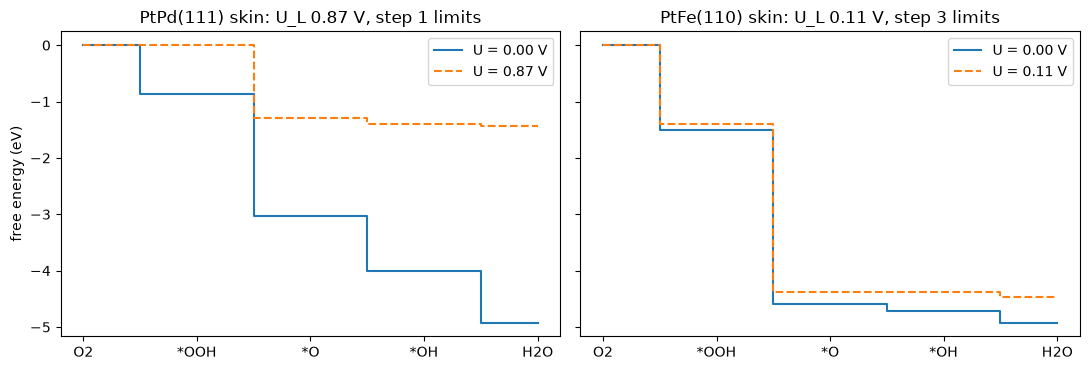

In [3]:
from src import dft as D
from src.functions import get_context, get_dft
ctx = get_context(llm=llm)
info = get_dft(ctx); dft = info["table"]; DEMO = not info["trusted"]
print("source:", info["source"], "| DEMO DATA" if DEMO else "| trusted provenance")
chk = dft[["step1", "step2", "step3", "step4"]].sum(axis=1)
print("steps sum to -4.92 eV for all rows:", bool(np.allclose(chk, -4.92)))
best, worst = dft.sort_values("U_L").iloc[-1], dft.sort_values("U_L").iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, row in zip(ax, (best, worst)):
    for U, ls in ((0.0, "-"), (float(row.U_L), "--")):
        a.step(range(5), D.free_energy_diagram(row, U).G_eV, where="mid", ls=ls, label=f"U = {U:.2f} V")
    a.set_xticks(range(5)); a.set_xticklabels(["O2", "*OOH", "*O", "*OH", "H2O"]); a.legend()
    a.set_title(f"{row.composition}({row.facet}) {row.structure}: U_L {row.U_L:.2f} V, step {int(row.limiting_step)} limits")
ax[0].set_ylabel("free energy (eV)")
savefig("02_free_energy_diagrams.png")
dft.groupby("limiting_step").size().rename("rows where this step limits")

**Reading it.** Which step limits tells you what to change: step 4 (OH removal) limiting means OH binds too strongly; step 1 (OOH formation) limiting means the surface binds too weakly; steps 2-3 involve O. The corrections added to the raw energies (0.35, 0.05 and 0.40 eV) are common defaults, not constants of nature.

---
## 2. DFT track — running small calculations yourself (ASE)

`src/dft_jobs.py` builds a slab, places OH, O and OOH on several sites, relaxes them with **any ASE calculator** and returns a table row with the reference-corrected energies and the right `provenance`: `emt_toy` (ASE's toy potential, workflow test only), `mlip` (MACE / CHGNet) or `dft` (your own calculator). **This code was not executed while the project was assembled (ASE and a DFT code were not available there);** the energy bookkeeping is unit-tested. The cell below runs the EMT self-test if ASE is installed and says so otherwise.

In [4]:
try:
    import ase
    from src.dft_jobs import run_candidates
    toy = run_candidates(pd.DataFrame({"composition": ["Pt"], "facet": ["111"], "structure": ["bulk"]}), "emt")
    print("EMT self-test row (provenance emt_toy: tests the workflow, not chemistry):")
    print(toy.round(3).to_string(index=False))
except ImportError:
    print("ASE is not installed here: pip install ase, then rerun this cell. To compute real values use a DFT calculator "
          "via get_calculator('custom', factory=...) or a machine-learned potential ('mace' / 'chgnet').")
except Exception as exc:
    print("ASE workflow raised", type(exc).__name__, ":", exc, "(report it; the unit tests cover only the energy bookkeeping)")

EMT self-test row (provenance emt_toy: tests the workflow, not chemistry):
      system_id composition facet structure provenance    code                reference   E_OH    E_O  E_OOH
EMT-Pt-111-bulk          Pt   111      bulk    emt_toy ASE/emt calculated here with emt -1.259 -0.919 -2.256


**Public data instead of your own calculations.** `src/dft_data.py` parses Catalysis-Hub records into the same table, accepting only equations referenced to H2O and H2 and only complete OH/O/OOH sets from one publication and functional. Its parser is tested on hand-written fixture strings; the live query needs a network and was not run here. Either route ends in `data/dft/dft_table.csv`.

---
## 2a. DFT track — ML screening with uncertainty

**Task:** predict the limiting potential of candidates *without* running their adsorption calculations, from cheap composition features (electronegativity, d-electron count, lattice mismatch, Pt fraction, facet, skin flag), with an uncertainty. **Validation:** leave-one-chemical-system-out, i.e. every Pt-Co row is held out, then every Pt-Ni row, and so on, the realistic test for a *new alloying element*. Four approaches (Ridge, Gradient Boosting, Random Forest, Gaussian process) and two targets: U_L directly, or ΔG_OH followed by the volcano.

In [5]:
from src.dft_ml import loso_evaluate, evaluate_baselines
res_direct, oof = loso_evaluate(dft, route="U_L direct")
res_volc, oof_v = loso_evaluate(dft, route="dG_OH -> volcano")
dft_models = pd.concat([res_direct, res_volc], ignore_index=True)
dft_models.to_csv(REPORTS_DIR / "dft_model_comparison.csv", index=False)
dft_models.round(3)

,model,route,MAE_U_L_V,spearman,top10pct_recall,coverage_90pct,mean_sd_V
0,Gaussian Process,U_L direct,0.071,0.741,0.000,0.928,0.107
1,Random Forest,U_L direct,0.074,0.705,0.182,0.811,0.081
2,Gradient Boosting,U_L direct,0.074,0.702,0.273,NaN,NaN
3,Ridge,U_L direct,0.088,0.739,0.091,NaN,NaN
4,Gaussian Process,dG_OH -> volcano,0.091,0.827,0.364,0.685,0.072
5,Ridge,dG_OH -> volcano,0.091,0.767,0.182,NaN,NaN
6,Gradient Boosting,dG_OH -> volcano,0.096,0.705,0.182,NaN,NaN
7,Random Forest,dG_OH -> volcano,0.098,0.732,0.273,0.667,0.081


Baselines (no ML):
                                        method  needs_DFT_for_candidate  spearman  top10pct_recall
       strain heuristic (compressive = better)                    False    -0.663            0.000
     electronegativity vs Pt (closer = better)                    False     0.595            0.091
                d-band centre (lower = better)                     True     0.256            0.364
ORACLE: volcano from the DFT dG_OH (needs DFT)                     True     0.842            0.182

Best ML: Gaussian Process (U_L direct): MAE 0.071 V, Spearman 0.74, top-10% recall 0.00


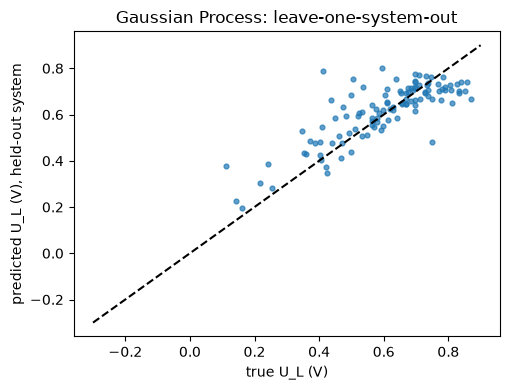

In [6]:
base = evaluate_baselines(dft)
base.to_csv(REPORTS_DIR / "dft_baselines.csv", index=False)
print("Baselines (no ML):"); print(base.round(3).to_string(index=False))
best_row = dft_models.sort_values("MAE_U_L_V").iloc[0]
print(f"\nBest ML: {best_row.model} ({best_row.route}): MAE {best_row.MAE_U_L_V:.3f} V, Spearman {best_row.spearman:.2f}, top-10% recall {best_row.top10pct_recall:.2f}")
fig, ax = plt.subplots(figsize=(5.2, 4))
m = best_row.model; ax.scatter(oof.U_L, oof[f"pred_{m}"], s=12, alpha=.7); ax.plot([-.3, .9], [-.3, .9], "k--")
ax.set(xlabel="true U_L (V)", ylabel="predicted U_L (V), held-out system", title=f"{m}: leave-one-system-out")
savefig("02_dft_loso_scatter.png")

**Decision.** The Gaussian process is the default screener: it has the lowest error, a ranking correlation similar to Ridge and, unlike the others, an uncertainty. Two cautions printed above: its **top-10% recall is low** (it separates good from poor candidates better than it picks the very best few), and the cheap single-quantity baselines can be wrong in sign on a given table. The uncertainty is only useful if calibrated (notebook 03 checks the coverage) and if new chemistry is flagged (notebook 03 tests it). On the synthetic demo table this section shows that the method runs end to end; it says nothing about real catalysts.

---
## 2b. DFT track — candidates, stability and the next calculation

The screener scores candidates **with no DFT values**, adds an out-of-distribution flag (a new chemical system, or far from any training row), stability flags from textbook potentials (a *heuristic*, labelled as such) and ranks which calculation to run next by an **upper confidence bound**.

In [7]:
from src.functions import dft_rank
from src.dft_ml import suggest_next_dft
cands = ["Pt3Ni", "Pt3Co", "Pt3Fe", "Pt3Ru", "PtNi"]
scored = dft_rank(ctx, cands, "111", "skin")
scored[["rank", "composition", "pred_U_L", "pred_sd", "confidence", "outside_training_distribution", "recommendation_allowed"]].round(3)

,rank,composition,pred_U_L,pred_sd,confidence,outside_training_distribution,recommendation_allowed
0,1,Pt3Ru,0.743,0.095,Low (outside the training distribution),True,False
1,2,Pt3Co,0.595,0.072,Moderate,False,False
2,3,Pt3Fe,0.559,0.075,Moderate,False,False
3,4,Pt3Ni,0.553,0.073,Moderate,False,False
4,5,PtNi,0.461,0.074,Moderate,False,False


In [8]:
print(scored[["composition", "recommendation"]].to_string(index=False))
print("\nStability flags (textbook heuristics, not DFT):")
for r in scored.itertuples(): print(" ", r.composition, [f["mechanism"] + " - " + f["detail"] for f in r.stability_flags])
print("\nNext DFT calculations (highest upper confidence bound):"); suggest_next_dft(scored, 3).round(3)

composition                                                                                 recommendation
      Pt3Ru NO RECOMMENDATION: the training table is not DFT/MLIP/literature data (synthetic or toy rows).
      Pt3Co NO RECOMMENDATION: the training table is not DFT/MLIP/literature data (synthetic or toy rows).
      Pt3Fe NO RECOMMENDATION: the training table is not DFT/MLIP/literature data (synthetic or toy rows).
      Pt3Ni NO RECOMMENDATION: the training table is not DFT/MLIP/literature data (synthetic or toy rows).
       PtNi NO RECOMMENDATION: the training table is not DFT/MLIP/literature data (synthetic or toy rows).

Stability flags (textbook heuristics, not DFT):
  Pt3Ru ['leaching of the less noble metal - Ru E0 = +0.46 V (a Pt skin may protect it)']
  Pt3Co ['leaching of the less noble metal - Co E0 = -0.28 V (a Pt skin may protect it)']
  Pt3Fe ['leaching of the less noble metal - Fe E0 = -0.45 V (a Pt skin may protect it)']
  Pt3Ni ['leaching of the less noble me

,composition,facet,pred_U_L,pred_sd,acquisition_UCB,confidence
0,Pt3Ru,111,0.743,0.095,0.837,Low (outside the training distribution)
1,Pt3Co,111,0.595,0.072,0.667,Moderate
2,Pt3Fe,111,0.559,0.075,0.634,Moderate


**Reading it.** `recommendation_allowed` is False whenever the training table is not DFT / MLIP / literature data, and the recommendation text says so. For a real table, candidates outside the training distribution get "run DFT first", the top-ranked candidates with moderate or high confidence get "confirm with DFT and check stability", and everything is an **ML prediction**, never a calculated or measured value.

---
## 3. Device layer — the physics core (no learning)

Each polarisation curve is read as an electrochemist reads it: **kinetic → ohmic → mass-transport** zones, descriptors, a voltage-loss budget, and peer-relative screening (compared with curves at the same pressure and humidity). This is the part of the product that says *where* the cell loses voltage, and it is fully explainable. The injected-fault evaluation of this screening is in notebook 03.

In [9]:
from src import physics
from src.data import load_polarization, eis_summary
pol = load_polarization()
curves = physics.build_curve_table(pol)
print(curves.shape)
curves[["curve_id", "test_family", "pressure", "relative_humidity", "intercept_v", "asr_ohm_cm2", "j_knee", "mt_loss_at_jmax", "p_max", "j_at_0p6"]].head()

(319, 21)


,curve_id,test_family,pressure,relative_humidity,intercept_v,asr_ohm_cm2,j_knee,mt_loss_at_jmax,p_max,j_at_0p6
0,0,Activation Test MEA Constant Current 0.25A,5.0,30.0,0.818487,0.194043,NaN,0.027678,869.70,1117.680000
1,1,Activation Test MEA Constant Current 0.25A,5.0,50.0,0.848862,0.140316,3310.0,0.094096,1244.40,1793.800000
2,2,Activation Test MEA Constant Current 0.25A,5.0,100.0,0.849601,0.138706,3280.0,0.104259,1257.72,1819.600000
3,3,Activation Test MEA Constant Current 0.25A,15.0,30.0,0.825730,0.169935,3030.0,0.048826,988.80,1322.000000
4,4,Activation Test MEA Constant Current 0.25A,15.0,50.0,0.842069,0.133681,3530.0,0.078028,1299.28,1820.196078


## 3a. The three-zone model of one curve

For each curve: (a) fit a straight line to the points between 0.45 V and 0.80 V, where kinetics have saturated and mass transport has not yet bent the curve; (b) the slope is an **apparent resistance** (ohmic plus part of the charge-transfer resistance); (c) the first point beyond the fit window that lies at least 30 mV under the line marks the **knee**; (d) the intercept deficit from the thermodynamic voltage (1.18 V near 75 °C) is the **kinetic loss**.

At a chosen reference current the voltage deficit splits exactly into three parts: kinetic + ohmic + mass transport = E_rev − V(j_ref).

{'n_points': 16, 'j_min': 41.4, 'j_max': 1980.0, 'v_at_jmin': 0.953, 'intercept_v': 0.828, 'asr_ohm_cm2': 0.268, 'fit_r2': 0.999, 'j_knee': 1880.0, 'mt_loss_at_jmax': 0.071, 'p_max': 631.96, 'j_at_pmax': 1480.0, 'j_at_0p6': 846.76, 'tafel_mv_dec': 235.465}
{'kinetic': 0.352, 'ohmic': 0.396, 'mass_transport': 0.005, 'total_deficit': 0.753, 'j_ref': 1480.0, 'v_ref': 0.427}


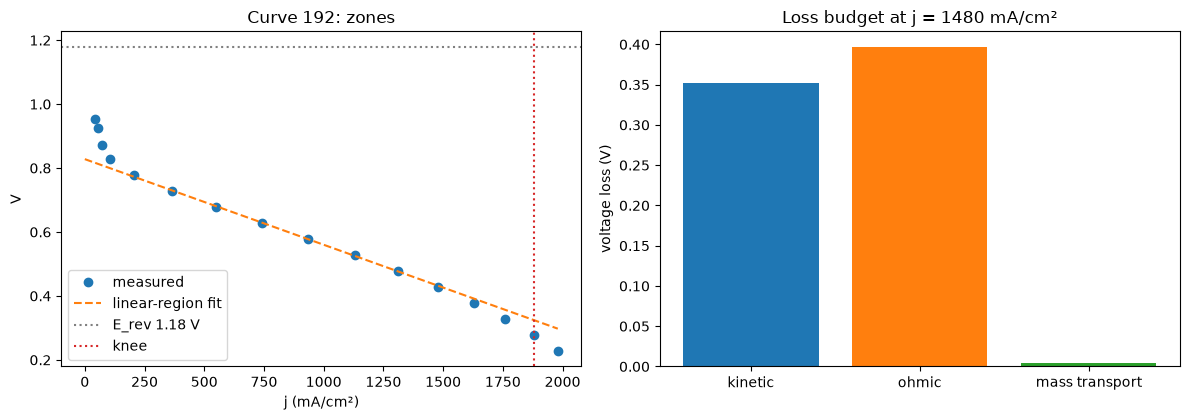

In [10]:
cid = curves.sort_values("p_max").curve_id.iloc[len(curves) // 2]      # a median curve
g = pol[pol.curve_id == cid].sort_values("current_density")
d = physics.curve_descriptors(g)
b = physics.breakdown_from_curve(g)
print({k: round(v, 3) for k, v in d.as_dict().items()})
print({k: round(v, 3) for k, v in b.items()})
assert abs(b["kinetic"] + b["ohmic"] + b["mass_transport"] - b["total_deficit"]) < 1e-9

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
j = np.linspace(0, g.current_density.max(), 100)
ax[0].plot(g.current_density, g.cell_voltage, "o", label="measured")
ax[0].plot(j, d.intercept_v - d.asr_ohm_cm2 * j / 1000, "--", label="linear-region fit")
ax[0].axhline(physics.E_REV_DEFAULT, color="grey", ls=":", label="E_rev 1.18 V")
if not np.isnan(d.j_knee): ax[0].axvline(d.j_knee, color="tab:red", ls=":", label="knee")
ax[0].set(xlabel="j (mA/cm²)", ylabel="V", title=f"Curve {cid}: zones"); ax[0].legend()
ax[1].bar(["kinetic", "ohmic", "mass transport"], [b["kinetic"], b["ohmic"], b["mass_transport"]], color=["tab:blue", "tab:orange", "tab:green"])
ax[1].set(ylabel="voltage loss (V)", title=f"Loss budget at j = {b['j_ref']:.0f} mA/cm²")
savefig("02_zones_one_curve.png")

## 3b. Descriptors across the dataset

In [11]:
curves[["intercept_v", "asr_ohm_cm2", "fit_r2", "j_knee", "mt_loss_at_jmax", "p_max", "j_at_0p6", "tafel_mv_dec"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
intercept_v,319.0,0.856,0.105,-0.108,0.820,0.835,0.867,1.440
asr_ohm_cm2,319.0,0.320,0.292,-2.622,0.183,0.285,0.402,1.972
fit_r2,319.0,0.967,0.110,0.007,0.985,0.998,0.999,1.000
j_knee,244.0,1924.402,1060.875,301.000,1100.000,1500.000,2930.000,4280.000
mt_loss_at_jmax,319.0,0.084,0.082,0.000,0.031,0.061,0.107,0.758
p_max,319.0,708.658,331.450,155.488,461.202,631.960,931.585,1687.000
j_at_0p6,319.0,982.620,462.235,217.304,663.770,873.000,1239.300,2580.200
tafel_mv_dec,319.0,219.645,57.145,82.611,190.922,222.092,248.918,493.812


Some curves have a non-linear mid-section (low `fit_r2`) or a non-physical slope. The three-zone model does not describe them, so the screening labels them **`unreliable_fit`** instead of forcing a zone on them. That is a deliberate honesty rule. The Tafel-like slope uses very few low-current points and is reported but not used for flags.

In [12]:
screened = physics.screen_curves(curves)
print(screened.dominant_zone.value_counts())
print()
print(pd.crosstab(screened.test_family, screened.dominant_zone))

dominant_zone
none              195
unreliable_fit     43
mass_transport     31
ohmic              28
kinetic            22
Name: count, dtype: int64

dominant_zone                                   kinetic  mass_transport  none  ohmic  unreliable_fit
test_family                                                                                         
Activation Test MEA Constant Current 0.25A            2               3    22      4               5
Activation Test MEA Constant Voltage 0.6V             1               3    15      2               6
Activation Test MEA Constant Voltage 0.6V-2           0               2    13      4               8
Activation Test MEA Constant Voltage 0.6V-3           1               5    15      2               4
Activation Test MEA Constant Voltage 0.6V-4           2               2    13      4               6
Activation Test MEA Cycling Potential                 2               5     8      0               3
Activation Test MEA Standard Protocol    

## 4. Peer-relative screening

A curve at 5 psig and 30% RH is *expected* to be weaker than one at 25 psig and 100% RH. So each curve is compared with its **peers** (same pressure and humidity; for files without those columns, the same test family). A robust z-score (median and MAD) says how much worse than its peers each zone is; a zone is flagged when the z-score is at least 1.5. The thresholds are screening heuristics, not validated failure criteria.

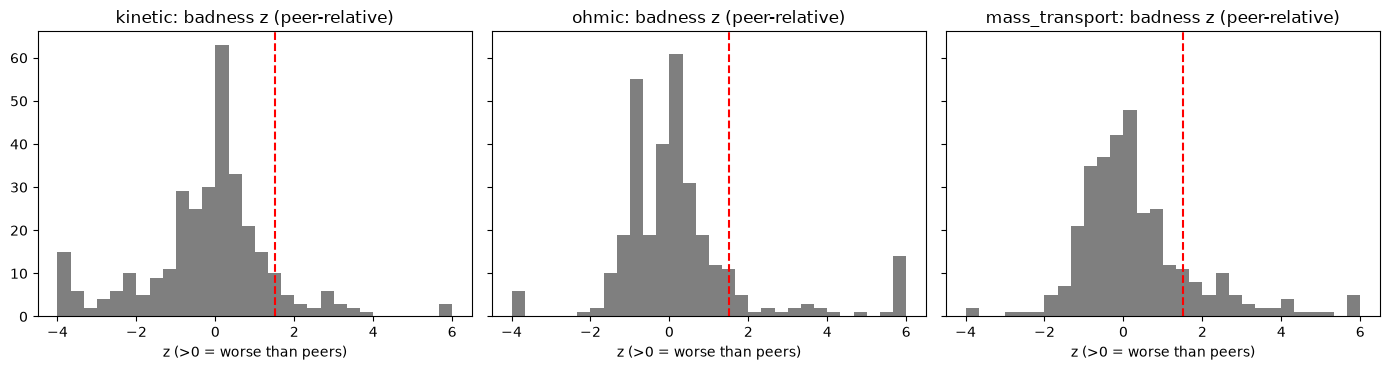

In [13]:
zones = list(physics.ZONE_INFO)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, z in zip(ax, zones):
    a.hist(screened[f"bad_{z}"].clip(-4, 6), bins=30, color="tab:gray")
    a.axvline(1.5, color="red", ls="--"); a.set_title(f"{z}: badness z (peer-relative)"); a.set_xlabel("z (>0 = worse than peers)")
savefig("02_badness_distributions.png")

In [14]:
# Worst curves per zone, with conditions
for z in zones:
    t = screened.sort_values(f"bad_{z}", ascending=False).head(3)
    print(f"\n{z.upper()}")
    print(t[["curve_id", "test_family", "pressure", "relative_humidity", "operating_set", f"bad_{z}", "p_max"]].round(2).to_string(index=False))


KINETIC
 curve_id                                    test_family  pressure  relative_humidity  operating_set  bad_kinetic  p_max
      222 Activation Test MEA Standard Protocol (Repeat)       NaN                NaN            1.0         8.66 765.00
       54      Activation Test MEA Constant Voltage 0.6V       NaN                NaN            1.0         6.59 770.15
       17     Activation Test MEA Constant Current 0.25A      25.0              100.0            NaN         6.45 226.10

OHMIC
 curve_id                                    test_family  pressure  relative_humidity  operating_set  bad_ohmic  p_max
      225 Activation Test MEA Standard Protocol (Repeat)       NaN                NaN            4.0      18.31 541.00
      195          Activation Test MEA Standard Protocol       NaN                NaN           16.0      13.92 370.99
       81    Activation Test MEA Constant Voltage 0.6V-2       NaN                NaN            1.0      13.92 337.70

MASS_TRANSPORT
 curve_i

## 4a. Diagnosis of one flagged curve

In [15]:
flagged = screened[screened.dominant_zone.isin(zones)].sort_values("p_max")
row = flagged.iloc[0]
diag = physics.diagnose_row(row)
for k, v in diag.items(): print(f"{k:>20}: {v}")

            curve_id: 18
       dominant_zone: ohmic
               flags: ['ohmic']
          severity_z: 8.85
          zone_label: Ohmic / linear zone (mid current)
    likely_component: membrane and ionomer hydration, contact resistance
 parameters_to_check: ['relative humidity', 'membrane compression', 'ionomer content', 'temperature']
            kb_query: high ohmic resistance membrane dehydration contact resistance HFR humidity
         descriptors: {'intercept_v': 0.8533, 'asr_ohm_cm2': 0.7782, 'j_knee': 581.0, 'mt_loss_at_jmax': 0.0628, 'p_max': 227.408, 'j_at_pmax': 488.0, 'j_at_0p6': 331.8, 'tafel_mv_dec': 375.8767}
          conditions: {'test_family': 'Activation Test MEA Constant Current 0.25A', 'pressure': None, 'relative_humidity': None, 'membrane_compression': None, 'nafion_percent': None, 'operating_set': np.float64(1.0)}


---
## 5. Model track — compare approaches for the voltage

Six approaches on the **same grouped folds** (whole files held out inside the training files), the same preprocessing, against the mean baseline of notebook 01: mean, Ridge, Random Forest, Extra Trees, Gradient Boosting and a small neural network (MLP 64-64). `fit_seconds_total` is the training time over the 5 folds. The test files stay untouched.

In [16]:
from src.data import load_polarization
from src.models import (FEATURES, TARGET, GROUP, holdout_split, model_zoo, compare_models, final_test,
                        model_size_kb, oof_curve_residuals, DesignSurrogate)
pol = load_polarization()
train, test = holdout_split(pol)
print(len(train), "train rows /", len(test), "test rows; features:", FEATURES)

3679 train rows / 1285 test rows; features: ['current_density', 'pressure', 'relative_humidity', 'membrane_compression', 'nafion_percent', 'operating_set', 'test_family']


In [17]:
cmp = compare_models(train)
cmp[["model", "MAE_V_mean", "MAE_V_std", "RMSE_V_mean", "R2_mean", "fit_seconds_total"]].round(4)

,model,MAE_V_mean,MAE_V_std,RMSE_V_mean,R2_mean,fit_seconds_total
0,Random Forest,0.0904,0.0178,0.1313,0.6579,1.3875
1,Extra Trees,0.0914,0.0204,0.1341,0.6403,1.0771
2,Gradient Boosting,0.0964,0.0142,0.1365,0.6335,7.6936
3,Ridge,0.1484,0.0403,0.1820,0.3401,0.0242
4,Neural net (MLP 64-64),0.1559,0.0191,0.1963,0.2511,3.6062
5,Mean baseline,0.1976,0.0028,0.2280,-0.0014,0.0245


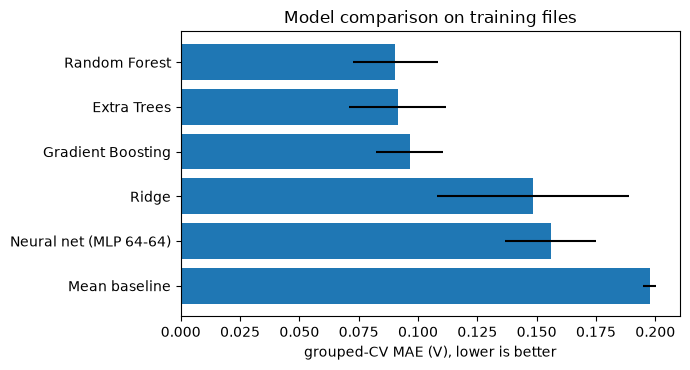

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(cmp.model[::-1], cmp.MAE_V_mean[::-1], xerr=cmp.MAE_V_std[::-1], color="tab:blue")
ax.set(xlabel="grouped-CV MAE (V), lower is better", title="Model comparison on training files")
savefig("03_model_comparison.png")
cmp.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)

**Reading the comparison.** Tree ensembles are clearly better than the linear model and the mean baseline: the relation between voltage, current and conditions is non-linear (a curved polarisation shape and interactions between pressure and humidity). The small neural network does *not* beat the trees: with about 3,700 correlated rows from 20 files, a network has little to learn that a forest cannot, and it needs more tuning. That is a finding, not a failure: the simplest strong model is kept. The spread between folds (`MAE_V_std`) is the honest size of the uncertainty: differences smaller than it should not be over-read.

---
## 5a. Model track — tune and choose

The best two approaches are within one fold-standard-deviation of each other, so the choice is made on **simplicity, time and size** as well as the score. A small grid on the winner (leaf size × features per split) is run on the same grouped folds, on the training files only.

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from src.models import make_preprocessor
grid = {f"RF leaf={leaf}, max_features={mf}": Pipeline([("pre", make_preprocessor(False)),
            ("m", RandomForestRegressor(200, min_samples_leaf=leaf, max_features=mf, n_jobs=-1, random_state=SEED))])
        for leaf in (1, 3, 6) for mf in (1.0, 0.6)}
tuned = compare_models(train, models=grid)
tuned[["model", "MAE_V_mean", "MAE_V_std", "fit_seconds_total"]].round(4)

,model,MAE_V_mean,MAE_V_std,fit_seconds_total
0,"RF leaf=6, max_features=0.6",0.0829,0.0154,0.7741
1,"RF leaf=3, max_features=0.6",0.0854,0.0159,0.7130
2,"RF leaf=6, max_features=1.0",0.0856,0.0170,0.8677
3,"RF leaf=3, max_features=1.0",0.0888,0.0177,0.9503
4,"RF leaf=1, max_features=0.6",0.0896,0.0179,0.8450
5,"RF leaf=1, max_features=1.0",0.0916,0.0178,1.0168


In [20]:
best_name = cmp.model.iloc[0]
print("Best approach by grouped CV:", best_name, "| best tuned RF:", tuned.model.iloc[0], f"({tuned.MAE_V_mean.iloc[0]:.4f} V)")
spread = tuned.MAE_V_std.iloc[0]
print(f"Tuning gain over the default RF: {cmp.MAE_V_mean.iloc[0] - tuned.MAE_V_mean.iloc[0]:+.4f} V, fold spread ~{spread:.3f} V")

Best approach by grouped CV: Random Forest | best tuned RF: RF leaf=6, max_features=0.6 (0.0829 V)
Tuning gain over the default RF: +0.0075 V, fold spread ~0.015 V


**Decision.** The best grid point improves the CV error by about 0.008 V, roughly half of the fold-to-fold spread (about 0.015 V), so the gain is **not clearly beyond the noise**. The **default Random Forest** is kept because it is the simplest to explain and the gain is not established; the tuned setting (`leaf=6, max_features=0.6`) is the first thing to try if more files become available. The small neural network is **not** chosen: with ~3,700 correlated rows from 20 files it cannot beat the trees. It is kept in the comparison because "deep learning did not help" is a finding. The final model is fitted on all training files and saved (time and size are reported in notebook 03).

In [21]:
import time, json, joblib
from src.models import FEATURES, TARGET, model_size_kb
final_pipe = model_zoo()[best_name]
t0 = time.perf_counter(); final_pipe.fit(train[FEATURES], train[TARGET]); fit_s = time.perf_counter() - t0
joblib.dump(final_pipe, MODELS_DIR / "voltage_model.joblib")
(MODELS_DIR / "voltage_model_meta.json").write_text(json.dumps({"model": best_name, "fit_seconds": fit_s,
        "size_mb": model_size_kb(final_pipe) / 1024, "features": FEATURES, "train_files": int(train.source_file.nunique())}, indent=1))
print(f"saved {best_name}: fit {fit_s:.1f} s on {len(train)} rows")

saved Random Forest: fit 0.3 s on 3679 rows


---
## 5b. Model track — what moves peak power, a second opinion, and a what-if surrogate

In [22]:
# Effect of each design variable on peak power, measured directly from the curves (no model)
from src.physics import build_curve_table
ct = build_curve_table(pol).dropna(subset=["nafion_percent"])
for v in ["pressure", "relative_humidity", "membrane_compression", "nafion_percent"]:
    print(v, ct.groupby(v).p_max.agg(["mean", "std", "count"]).round(0).to_dict("index"))

pressure {5.0: {'mean': 341.0, 'std': 64.0, 'count': 14}, 15.0: {'mean': 416.0, 'std': 87.0, 'count': 14}, 25.0: {'mean': 482.0, 'std': 84.0, 'count': 14}}
relative_humidity {30.0: {'mean': 402.0, 'std': 116.0, 'count': 12}, 50.0: {'mean': 419.0, 'std': 92.0, 'count': 12}, 80.0: {'mean': 371.0, 'std': 60.0, 'count': 6}, 100.0: {'mean': 439.0, 'std': 97.0, 'count': 12}}
membrane_compression {5.0: {'mean': 357.0, 'std': 60.0, 'count': 24}, 12.0: {'mean': 488.0, 'std': 86.0, 'count': 18}}
nafion_percent {20.0: {'mean': 415.0, 'std': 89.0, 'count': 21}, 25.0: {'mean': 411.0, 'std': 106.0, 'count': 21}}


**Reading the table.** Peak power rises clearly with pressure (about 340 → 480 mW/cm² from 5 to 25 psig) and with membrane compression (about 360 → 490 mW/cm² from 5% to 12%), with spreads of 60-90 mW/cm² inside each level. Humidity is not monotonic (the 80% level has only 6 curves), and **20% vs 25% Nafion shows no net difference in mean peak power** (about 415 vs 411): any ionomer effect depends on the other conditions, so a single "best ionomer content" cannot be read from these means. This also explains why Nafion % has near-zero permutation importance.

## 5c. Second opinion: which curves under-perform their conditions?

For each curve, a model trained on the *other* files predicts the voltage at every point; the mean residual (measured − predicted) tells whether the curve is better or worse than its conditions suggest. This is independent of the physics rules in notebook 02.

In [23]:
resid = oof_curve_residuals(pol)
resid["underperforms"] = resid.resid_z <= -1.5
from src.functions import get_context
ctx = get_context()
both = ctx.curves[["curve_id", "dominant_zone", "ml_underperforms"]].copy()
both["physics_flag"] = both.dominant_zone.isin(["kinetic", "ohmic", "mass_transport"])
print(pd.crosstab(both.physics_flag, both.ml_underperforms, rownames=["physics flag"], colnames=["ML under-performs"]))

ML under-performs  False  True 
physics flag                   
False                232      6
True                  79      2


The two methods **barely overlap**: physics flags many curves (weak in one zone relative to peers), the ML residual flags only a handful, and just two curves are flagged by both. They answer different questions: *which zone is unusually lossy compared with peers* versus *is the whole curve worse than a global model expects from its conditions*. Low overlap therefore does **not** validate either method; it says the ML residual is a conservative extra check (a curve flagged by both deserves attention first), not a confirmation of the physics flags. Neither is ground truth.

A small surrogate is trained on the Nafion standard test, the only file where pressure, humidity, **compression and ionomer content** all vary. It is checked leave-one-curve-out and **refuses** conditions outside the measured ranges.

In [24]:
sur = DesignSurrogate().fit(pol)
print(f"leave-one-curve-out MAE = {sur.cv_mae_:.3f} V; measured levels: {sur.levels}")
grid = sur.screen_grid()
grid.head(6).round(1)

leave-one-curve-out MAE = 0.027 V; measured levels: {'pressure': [5.0, 15.0, 25.0], 'relative_humidity': [30.0, 50.0, 80.0, 100.0], 'membrane_compression': [5.0, 12.0], 'nafion_percent': [20.0, 25.0]}


,pressure,relative_humidity,membrane_compression,nafion_percent,pred_p_max,pred_j_at_0p6
0,25.0,100.0,12.0,25.0,630.4,890.0
1,25.0,80.0,12.0,25.0,608.0,855.9
2,25.0,50.0,12.0,25.0,581.7,757.0
3,25.0,30.0,12.0,25.0,577.9,670.1
4,25.0,80.0,12.0,20.0,564.9,724.6
5,15.0,100.0,12.0,25.0,564.6,770.2


In [25]:
from src.functions import empirical_best, suggest_changes
print("Best MEASURED conditions (no model):"); print(empirical_best(ctx, 3).round(0))
print("\nRanked single changes starting from 5 psig, 30 % RH, 5 % compression, 20 % Nafion:")
suggest_changes(ctx, 5, 30, 5, 20).head(5).round(1)

Best MEASURED conditions (no model):
   pressure  relative_humidity  membrane_compression  nafion_percent  p_max  j_at_0p6
0      25.0              100.0                  12.0            25.0  631.0     924.0
1      25.0               30.0                  12.0            20.0  607.0     389.0
2      25.0               50.0                  12.0            25.0  572.0     718.0

Ranked single changes starting from 5 psig, 30 % RH, 5 % compression, 20 % Nafion:


,change,pred_p_max,gain_mW_cm2
0,membrane_compression: 5 -> 12,443.8,111.0
1,pressure: 5 -> 25,431.1,98.2
2,relative_humidity: 30 -> 100,367.2,34.3
3,pressure: 5 -> 15,360.4,27.5
4,relative_humidity: 30 -> 80,359.1,26.2


Extrapolation refused: pressure=40 is outside the measured range [5, 25]: no extrapolation allowed


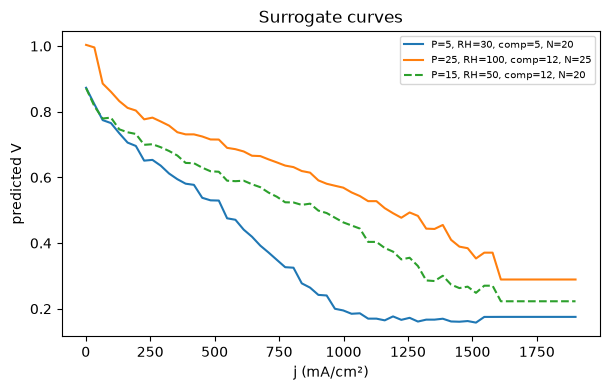

In [26]:
fig, ax = plt.subplots(figsize=(6.2, 4))
for cond, ls in [((5, 30, 5, 20), "-"), ((25, 100, 12, 25), "-"), ((15, 50, 12, 20), "--")]:
    c = sur.predict_curve(*cond); ax.plot(c.current_density, c.cell_voltage, ls, label=f"P={cond[0]}, RH={cond[1]}, comp={cond[2]}, N={cond[3]}")
ax.set(xlabel="j (mA/cm²)", ylabel="predicted V", title="Surrogate curves"); ax.legend(fontsize=7)
savefig("03_surrogate_curves.png")
try:
    sur.predict_curve(pressure=40, relative_humidity=50, membrane_compression=5, nafion_percent=20)
except ValueError as e:
    print("Extrapolation refused:", e)

**Caveats stated plainly.** (1) One MEA design in one laboratory. (2) The best predicted condition coincides with the best measured one, which is reassuring but it is the same data. (3) Predicted gains are interpolations; confirm with a measurement. (4) Nothing here says anything about catalyst *chemistry*.

---
## 5d. Model track — comment classifiers (the second model)

Lab comments become structured signals. **Important:** the training corpus is **synthetic** (72 hand-written observation phrases, `src/reviews.py`); no redistributable corpus of PEMFC lab comments exists. To keep the scores honest the split is **by phrase**, so unseen wording is the test. Approaches: majority class, a transparent lexicon rule, TF-IDF + logistic regression with and without lexicon features.

In [27]:
from src.reviews import (generate_synthetic_reviews, train_review_models, lexicon_sentiment, analyze_comment,
                         extract_rules, ReviewStore, summarise_comments, ASPECTS, SENTIMENTS)
df = generate_synthetic_reviews()
print(df.shape, "| distinct observation phrases:", df.phrase_id.nunique())
df.sample(6, random_state=1)[["text", "sentiment", "aspect", "rating"]]

(216, 7) | distinct observation phrases: 72


,text,sentiment,aspect,rating
78,"Activation Test MEA Constant Voltage 0.6V, 5 p...",neutral,ohmic,3
33,"Activation Test MEA Standard Protocol, 5 psig,...",neutral,cost,3
34,Performance after cycling was close to the sta...,neutral,durability,3
62,Run at 15 psig and 30% RH - No measurable deca...,positive,durability,4
97,"Standard Test of Nafion Membrane 112, 5 psig, ...",negative,reproducibility,2
95,"Activation Test MEA Constant Current 0.25A, 15...",neutral,mass_transport,3


In [28]:
print(df.groupby(["aspect", "sentiment"]).size().unstack())

sentiment        negative  neutral  positive
aspect                                      
cost                   12       12        12
durability             12       12        12
kinetics               12       12        12
mass_transport         12       12        12
ohmic                  12       12        12
reproducibility        12       12        12


## 6. Evaluation design

Group split by `phrase_id` (5 random splits, 25% of phrases held out each time). Metric: **macro-F1**, because the cost of missing a *negative* comment equals the cost of missing a positive one here and classes are balanced. Baselines: majority class, a transparent lexicon rule, then TF-IDF + logistic regression with and without lexicon features.

In [29]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score
from sklearn.dummy import DummyClassifier
rows = []
for seed in range(5):
    tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=seed).split(df, groups=df.phrase_id))
    a, b = df.iloc[tr], df.iloc[te]
    m = train_review_models(a)
    dummy = DummyClassifier(strategy="most_frequent").fit(a.text, a.sentiment)
    rows.append({
        "seed": seed,
        "sent: majority": f1_score(b.sentiment, dummy.predict(b.text), average="macro"),
        "sent: lexicon rule": f1_score(b.sentiment, [lexicon_sentiment(t) for t in b.text], average="macro"),
        "sent: TF-IDF+lexicon LR": f1_score(b.sentiment, m.sentiment.predict(b.text), average="macro"),
        "aspect: TF-IDF LR": f1_score(b.aspect, m.aspect.predict(b.text), average="macro"),
        "aspect: chance (1/6)": 1 / 6})
res = pd.DataFrame(rows).set_index("seed")
summary = pd.DataFrame({"mean": res.mean(), "std": res.std()}).round(3)
summary

,mean,std
sent: majority,0.149,0.019
sent: lexicon rule,0.839,0.089
sent: TF-IDF+lexicon LR,0.922,0.035
aspect: TF-IDF LR,0.497,0.078
aspect: chance (1/6),0.167,0.000


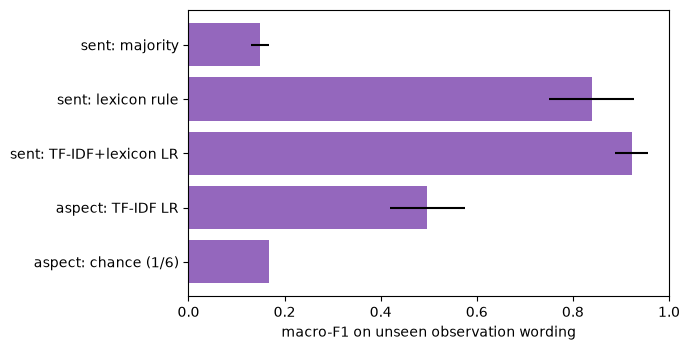

In [30]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(summary.index[::-1], summary["mean"][::-1], xerr=summary["std"][::-1], color="tab:purple")
ax.set(xlabel="macro-F1 on unseen observation wording", xlim=(0, 1))
savefig("05_review_models.png")
summary.to_csv(REPORTS_DIR / "review_model_scores.csv")

**Reading the result.** Sentiment generalises well to unseen wording (a domain lexicon plus TF-IDF reaches roughly 0.9 macro-F1; the plain lexicon rule is already far above the majority baseline). **Aspect** is much harder: with only four phrasings per aspect and sentiment, the classifier has seen too little vocabulary and lands well above chance (1/6) but far from reliable. In the app the aspect tag is a *suggestion*, and the symptom keywords and numbers extracted by rules are shown next to it. Real comments would need real labelled data (a few hundred labelled comments from your lab would be a better investment than a bigger model).

## 6a. Read the errors

In [31]:
tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(df, groups=df.phrase_id))
m = train_review_models(df.iloc[tr]); b = df.iloc[te].copy()
b["pred_aspect"] = m.aspect.predict(b.text); b["pred_sent"] = m.sentiment.predict(b.text)
wrong = b[(b.pred_aspect != b.aspect) | (b.pred_sent != b.sentiment)].drop_duplicates("phrase_id")
wrong[["text", "aspect", "pred_aspect", "sentiment", "pred_sent"]].head(8).to_string(index=False)

'                                                                                                                                   text          aspect    pred_aspect sentiment pred_sent\n                                             Run at 25 psig and 30% RH - The cheaper variant performed nearly as well. Worth repeating.            cost     durability  positive  positive\n                  Activation Test MEA Constant Current 0.25A, 25 psig, 30% RH: The repeat run confirmed the earlier curve. Encouraging. reproducibility          ohmic  positive  positive\n                          Standard Test of Nafion Membrane 112, 25 psig, 100% RH: Results changed after the same protocol was repeated. reproducibility     durability  negative  negative\n                       Standard Test of Nafion Membrane 112: The improvement does not justify the added catalyst cost. Needs follow-up.            cost       kinetics  negative   neutral\n                                                           

Typical failures: comments whose key words never appeared in training ("overlapped", "shallow"), and comments that mix aspects ("resistance dropped once humidity was raised" touches ohmic *and* operating conditions). Negation and hedging ("not reproducible", "within normal scatter") are fragile in bag-of-words models.

## 6b. Analyse a new comment

`analyze_comment` combines the classifiers with rule-based extraction of numbers and symptoms. If an LLM is configured it also returns a JSON extraction (the LLM is only asked to restate what the comment says).

In [32]:
# ============================================================
# REINITIALIZE PEMFC-CATHODE-AI LIVE LLM
# ============================================================

from src.llm import connect_llm
from src.config import get_llm_settings

# Load current configuration
cfg = get_llm_settings()

# Verify credentials
assert cfg.has_key, (
    "OpenAI API key not detected. Check your .env file."
)

# Initialize a fresh client
llm = connect_llm(
    model=cfg.model,
    ask=False
)

# Verify actual API connectivity
assert llm.available, (
    f"LLM initialization failed: {llm.status()}"
)

ok, msg = llm.ping()

if not ok:
    cfg = get_llm_settings()
    assert cfg.has_key, "OpenAI API key not detected. Check your .env file."

    # Use a model ID available to your account.
    llm = connect_llm(model="gpt-6-luna", ask=False)

    ok, msg = llm.ping()
    if not ok:
        print(f"Live LLM unavailable; continuing offline: {msg}")
        llm = None

    print("=" * 55)
    print("LLM INITIALIZATION")
    print("=" * 55)
    print("Mode:", "LIVE" if llm is not None else "OFFLINE")
    if llm is not None:
        print("Model:", llm.model)
        print("Available:", llm.available)
    print("Connection:", msg)
    print("=" * 55)

print("=" * 55)
print("LIVE LLM INITIALIZATION SUCCESSFUL")
print("=" * 55)
print("Model:", llm.model)
print("Available:", llm.available)
print("Connection:", msg)
print("=" * 55)

LLM INITIALIZATION
Mode: LIVE
Model: gpt-6-luna
Available: True
Connection: live call succeeded with model gpt-6-luna (13+4 tokens)
LIVE LLM INITIALIZATION SUCCESSFUL
Model: gpt-6-luna
Available: True
Connection: live call succeeded with model gpt-6-luna (13+4 tokens)


In [33]:
# Re-run the review model training and analysis with the live LLM
models = train_review_models(df)
print("LLM:", llm.status() if llm is not None else "offline (not configured)")
for text in ["At 5 psig and 30% RH the voltage collapsed at high current and the signal was noisy.",
             "Resistance climbed during the 0.6 V hold and the membrane seemed dry; HFR doubled.",
             "Repeat runs overlapped almost perfectly across three assemblies."]:
    a = analyze_comment(text, models, llm)
    print(f"\n{text}\n -> sentiment {a['sentiment']} ({a['sentiment_confidence']:.2f}); aspects {[(x, round(p, 2)) for x, p in a['aspects']]}"
          f"; zone {a['suspected_zone']}; numbers {a['numbers']}; symptoms {a['symptoms']}")

LLM: online · model gpt-6-luna

At 5 psig and 30% RH the voltage collapsed at high current and the signal was noisy.
 -> sentiment negative (1.00); aspects [('mass_transport', 0.77), ('kinetics', 0.07)]; zone mass_transport; numbers {'pressure_psig': [5.0], 'relative_humidity_pct': [30.0]}; symptoms ['noisy_signal']

Resistance climbed during the 0.6 V hold and the membrane seemed dry; HFR doubled.
 -> sentiment negative (1.00); aspects [('ohmic', 0.76), ('durability', 0.09)]; zone ohmic; numbers {'voltage_V': [0.6]}; symptoms ['dehydration']

Repeat runs overlapped almost perfectly across three assemblies.
 -> sentiment positive (0.97); aspects [('reproducibility', 0.89), ('durability', 0.03)]; zone unknown; numbers {}; symptoms []


**Store, link and summarise.** Comments typed into the app go to a git-ignored JSON-lines file; the summary cites comment numbers.

In [34]:
import tempfile
store = ReviewStore(Path(tempfile.mkdtemp()) / "demo.jsonl")          # a throw-away store for this notebook
for text, rating, fam in [("Voltage collapsed at high current, looks like flooding.", 2, "Standard Test of Nafion Membrane 112"),
                          ("Resistance climbed during the hold, membrane dry.", 2, "Activation Test MEA Standard Protocol"),
                          ("Repeat run confirmed the earlier curve.", 5, "Activation Test MEA Standard Protocol")]:
    store.add(text, rating, fam, analyze_comment(text, models))
d = store.load()
print(d[["text", "sentiment", "top_aspect", "suspected_zone"]].to_string(index=False))
summary_text, usage = summarise_comments(d, llm)
print("\n", summary_text)

                                                   text sentiment      top_aspect suspected_zone
Voltage collapsed at high current, looks like flooding.  negative  mass_transport mass_transport
      Resistance climbed during the hold, membrane dry.  negative           ohmic          ohmic
                Repeat run confirmed the earlier curve.  positive reproducibility        unknown

 **Recurring problems:** No problem is shown recurring across the comments; one test reports voltage collapse at high current that looked like flooding [C1], while another reports rising resistance during the hold and a dry membrane [C2].

**What went well:** A repeat run confirmed the earlier curve [C3].

**Disagreements:** No explicit disagreement is reported; the flooding-like behavior and dryness were noted in separate tests [C1][C2].


---
## 7. LLM track — retrieval over the knowledge notes

Pipeline: notes → chunks (with metadata) → retriever (BM25, dense, hybrid) → relevance gate → grounded prompt with numbered sources → LLM or offline extractive answer → citation check.

In [35]:
from src.rag import (load_documents, chunk_documents, BM25Retriever, DenseRetriever, HybridRetriever,
                     build_retriever, answer_question, query_coverage, verify_answer, tokenize)
docs = load_documents()
print(len(docs), "notes;", sum(len(d['text'].split()) for d in docs), "words")
pd.DataFrame(docs)[["id", "title", "topic", "evidence"]].head(12)

46 notes; 3914 words


,id,title,topic,evidence
0,K01,ORR kinetics at the PEMFC cathode,kinetics,textbook
1,K02,Pt/C as the baseline cathode catalyst,catalyst,textbook
2,K03,"Platinum alloy cathode catalysts (PtCo, PtNi)",catalyst,literature
3,K04,Structured and shape-controlled Pt catalysts,catalyst,literature
4,K05,Platinum-group-metal-free (Fe-N-C) cathodes,catalyst,literature
5,K06,Carbon support corrosion,durability,textbook
6,K07,"Platinum dissolution, ripening and ECSA loss",durability,textbook
7,K08,Ionomer content in the cathode catalyst layer,catalyst-layer,literature
8,K09,Flooding versus dehydration (water management),water,textbook
9,K10,Effect of operating pressure,operating,textbook


In [36]:
whole = chunk_documents(docs)
small = chunk_documents(docs, chunk_words=40)
print(len(whole), "whole-note chunks;", len(small), "40-word chunks")
print(small[0].chunk_id, "->", small[0].text[:120], "...")

46 whole-note chunks; 150 40-word chunks
K01-0 -> The oxygen reduction reaction (ORR) at the cathode is far slower than hydrogen oxidation at the anode, so the cathode ca ...


In [37]:
bm25 = BM25Retriever(whole)
dense = DenseRetriever(whole)           # backend chosen automatically
hybrid = HybridRetriever(whole)
print("dense backend:", dense.backend)
q = "My cathode voltage collapses at high current and the signal is noisy. Why?"
for r in [bm25, dense, hybrid]:
    print(f"{r.name:32s}", [(h.doc_id, round(h.score, 2)) for h in r.search(q, k=4)])

dense backend: lsa
bm25                             [('K09', 8.45), ('K14', 6.33), ('K01', 5.15), ('K19', 4.72)]
dense-lsa                        [('K09', 0.65), ('K14', 0.54), ('K01', 0.34), ('K08', 0.32)]
hybrid(bm25+dense-lsa)           [('K09', 0.03), ('K14', 0.03), ('K01', 0.03), ('K19', 0.03)]


A metadata filter narrows the search to one topic (useful when the diagnosis already says which zone):

In [38]:
for h in hybrid.search("how to measure it", k=3, topic="metrics"):
    print(h.doc_id, h.chunk.title)

K23 Measuring ECSA by hydrogen underpotential deposition
K22 Metrics used to compare cathode catalysts


## 7a. A relevance gate before the LLM

`query_coverage` is the share of the question's content words found in the retrieved text. When it is low, the question is probably **outside** the knowledge base, and the system abstains **without calling the LLM** (cheaper, and it cannot hallucinate).

In [39]:
tests = ["How can I tell flooding from dehydration?",
         "What is the stack lifetime of the Toyota Mirai?",
         "Who won the football world cup in 2018?"]
for t in tests:
    hits = hybrid.search(t, k=4)
    print(f"coverage {query_coverage(t, hits):.2f} | {t}")

coverage 1.00 | How can I tell flooding from dehydration?
coverage 0.25 | What is the stack lifetime of the Toyota Mirai?
coverage 0.00 | Who won the football world cup in 2018?


## 7b. LLM track — grounded answers, offline and live

The prompt gives numbered sources and four rules: cite every claim as `[S1]`, answer `NOT_IN_KB` when the sources are insufficient, never invent numbers or links, separate data from literature. Offline, the fallback copies the best-matching sentences with their citations: less fluent, but it cannot invent anything. Live, the **same sources and the same citation check** apply.

In [40]:
print("LLM status:", llm.status())
a = answer_question("How can I tell flooding from membrane dehydration?", hybrid, llm)
print(a.mode, "| cited sources:", a.cited, "->", a.cited_doc_ids)
print(a.answer)

LLM status: online · model gpt-6-luna
llm | cited sources: [1] -> ['K09']
Flooding typically causes an early mass-transport knee at high current, sometimes with noisy or falling voltage, and may improve after a purge, higher gas flow, or higher temperature. [S1] Membrane dehydration instead raises high-frequency resistance and steepens the linear region of the polarization curve, and may improve with humidification. [S1] Both can occur in the same cell at different current densities. [S1]


In [41]:
a = answer_question("What is the stack lifetime of the Toyota Mirai?", hybrid, llm)
print(a.mode, "| abstained:", a.abstained); print(a.answer)

abstained | abstained: True
NOT_IN_KB: the knowledge base does not cover this question (query coverage 0.25 < 0.34).


### Offline and live, side by side

The same question, answered by the extractive fallback and (if connected) by the LLM with the same sources and the same citation check.

In [42]:
from src.rag import answer_question
q = "Why are Fe-N-C cathodes prone to flooding and early mass-transport limits?"
off = answer_question(q, hybrid, None)
live = answer_question(q, hybrid, llm) if MODE == "LIVE" else None
print("OFFLINE (extractive):", off.answer, "\n")
print("LIVE (" + llm.model + "):", live.answer if live else "not connected: set the key in the connection panel above")
if live: print("usage:", live.usage.as_dict(), "| invalid citations:", live.invalid_citations, "| unsupported links:", live.unsupported_links)

OFFLINE (extractive): Flooding fills cathode pores or the gas diffusion layer with liquid water and blocks oxygen: it appears as an early mass-transport knee at high current, sometimes with noisy or falling voltage, and often recovers after a purge, higher flow or higher temperature. [S2] Thick layers make water and oxygen transport harder, which shows up as an early mass-transport knee. [S1] The ECSIM dataset reports H2/O2 operation, so a mass-transport limit measured there probably understates the limit in air. [S3] 

LIVE (gpt-6-luna): Literature notes say Fe-N-C has a lower volumetric density of active sites than Pt/C, so its cathode layers must be thicker; these thicker layers make water and oxygen transport harder and can produce an early mass-transport knee [S1]. Flooding occurs when liquid water blocks cathode pores or the gas diffusion layer, restricting oxygen transport, but the sources do not establish that Fe-N-C is intrinsically more prone to flooding [S2]. ECSIM contains 

### Guardrail demonstration

A model answer with a fabricated source number and a made-up DOI is caught by `verify_answer` (this is a hand-written string, not a model output):

In [43]:
hits = hybrid.search("flooding", k=3)
verify_answer("Water blocks pores [S1][S9]. See 10.9999/made.up for details.", hits)

([1, 9], [9], ['10.9999/made.up'])

## 8. The knowledge base inside an index (Additional: Chroma)

For a persistent vector index (as in the course material) the same chunks can be stored with `chromadb`. The app does not need it because the base is tiny; the cell is skipped when `chromadb` is missing. The index lives in `models/index/` (git-ignored) and is rebuilt by this cell.

In [44]:
try:
    import chromadb
    client = chromadb.PersistentClient(path=str(MODELS_DIR / "index"))
    col = client.get_or_create_collection("pemfc_notes")
    if col.count() == 0:
        col.add(ids=[c.chunk_id for c in whole], documents=[c.title + ". " + c.text for c in whole],
                metadatas=[{"doc_id": c.doc_id, "topic": c.topic, "evidence": c.evidence} for c in whole])
    res = col.query(query_texts=["flooding at high current"], n_results=3)
    print([m["doc_id"] for m in res["metadatas"][0]])
except ImportError:
    print("chromadb not installed: skipped (pip install chromadb)")

['K09', 'K18', 'K29']


---
## 8a. LLM track — the agent and the generated report

Seven tools (diagnose a curve, search notes, predict, suggest changes, analyse a comment, summarise comments, list curves). The LLM chooses tools; without a key a keyword router calls the **same tools**. The answer is checked for note ids, DOIs and curve ids that no tool returned.

In [45]:
from src.functions import get_context, list_curves, troubleshooting_report
from src.agent import TOOLS, run_agent, run_tool, AGENT_SYSTEM
print("LLM status:", llm.status())
ctx = get_context(llm=llm)
print("tools:", [t["function"]["name"] for t in TOOLS])

LLM status: online · model gpt-6-luna
tools: ['search_knowledge', 'list_curves', 'diagnose_curve', 'predict_performance', 'suggest_changes', 'analyze_comment', 'summarize_comments', 'dft_rank_candidates', 'dft_descriptors', 'next_dft_calculation']


## 8b. The agent's instructions

In [46]:
print(AGENT_SYSTEM)

You are the PEMFC Cathode Diagnosis Agent for an electrochemistry team.
You help find WHERE a cell fails (kinetic, ohmic or mass-transport zone), WHICH parameters matter,
HOW to troubleshoot, and WHAT to improve, using the ECSIM Nafion/MEA dataset (Pt/C cathodes, H2/O2).
Rules:
- Call tools for every number, curve or literature claim. Never compute or recall numbers yourself.
- Cite knowledge-base notes as [K07] style ids and curves as 'curve 12'. Cite only ids returned by tools.
- Never invent DOIs, URLs, papers or catalyst performance numbers. The only DOI you may mention is 10.26434/chemrxiv.11902023.
- DFT rules: separate three kinds of value and name them: calculated (DFT or database), ML-predicted (with its
  uncertainty) and textbook heuristics. Never invent an adsorption energy, a limiting potential or a source. If a
  tool says recommendation_allowed is false (demo or toy data), say there is no recommendation and why. A model
  prediction outside the training chemistry is a re

## 8c. Tools are plain Python (testable without any LLM)

In [47]:
print(list_curves(ctx, flagged_only=True, limit=5).round(2).to_string(index=False))
r = run_tool(ctx, "suggest_changes", dict(pressure=5, relative_humidity=30, membrane_compression=5, nafion_percent=20))
print(r["baseline_p_max"], r["ranked_changes"][:2])
print(run_tool(ctx, "predict_performance", dict(pressure=60, relative_humidity=30, membrane_compression=5, nafion_percent=20)))

 curve_id                                test_family  pressure  relative_humidity  operating_set  p_max  dominant_zone  resid_z
       18 Activation Test MEA Constant Current 0.25A       NaN                NaN            1.0 227.41          ohmic    -1.13
       19 Activation Test MEA Constant Current 0.25A       NaN                NaN            2.0 299.56          ohmic    -1.22
      254       Standard Test of Nafion Membrane 112       5.0               80.0            NaN 305.53        kinetic    -1.36
      249       Standard Test of Nafion Membrane 112      15.0               50.0            NaN 316.35          ohmic    -1.17
      303       Standard Test of Nafion Membrane 112       5.0               80.0            NaN 319.48 mass_transport    -0.77
332.8 [{'change': 'membrane_compression: 5 -> 12', 'pred_p_max': 443.8, 'gain_mW_cm2': 111.0}, {'change': 'pressure: 5 -> 25', 'pred_p_max': 431.1, 'gain_mW_cm2': 98.2}]
{'error': 'pressure=60.0 is outside the measured range [5, 25]

The last call asks for a pressure outside the measured design; the tool **returns an error instead of extrapolating**, and an LLM would see that message and has to say so.

## 8d. Ask the agent

With a key, the model decides which tools to call. Without one, the offline router answers the same questions from the same tools. Both return the **tool trace**.

In [48]:
cid = int(list_curves(ctx, flagged_only=True, limit=1).curve_id.iloc[0])
questions = [f"Diagnose curve {cid} and tell me what to check next.",
             "At 5 psig and 30% RH, what single change would improve power most?",
             "How can I tell flooding from membrane dehydration?",
             "What is the market price of platinum today?"]
for q in questions:
    res = run_agent(ctx, q)
    print(f"\nQ: {q}\n   mode={res.mode} tools={[s['tool'] for s in res.steps]} problems={res.problems}")
    print("  ", res.answer[:600].replace("\n", " "))


Q: Diagnose curve 18 and tell me what to check next.
   mode=offline-router tools=['diagnose_curve'] problems=['LLM call failed, answered offline: BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions. To use function tools, use /v1/responses or set']
   Curve 18: Ohmic / linear zone (mid current). Likely component: membrane and ionomer hydration, contact resistance. Severity z = 8.85. Agreement between methods: physics flag only. Parameters to check: relative humidity, membrane compression, ionomer content, temperature. [K12] Nafion 112 is a membrane about 50 micrometres thick. [K11] Higher cell temperature speeds ORR kinetics and mass diffusion, but it lowers the relative humidity of the gas at fixed water content and can dry the membrane.  (Offline router: no LLM key set, answers are assembled from templates and tool outputs.)

Q: At 5 psig and 30% RH, what single change would improve power most?
   mode=off

### Offline router vs live agent on the same question

In [49]:
import dataclasses
q = "At 5 psig and 30% RH, what single change would improve power most, and how sure are you?"
off = run_agent(dataclasses.replace(ctx, llm=None), q)
print("OFFLINE ROUTER:", off.answer[:500], "\n")
if MODE == "LIVE":
    live = run_agent(ctx, q)
    print("LIVE AGENT (" + llm.model + "):", live.answer, "\n tools:", [s["tool"] for s in live.steps], "| problems:", live.problems, "| usage:", live.usage.as_dict())
else:
    print("LIVE AGENT: not connected (see the connection panel at the top)")

OFFLINE ROUTER: At 5 psig, 30% RH, 5% compression, 25% Nafion the surrogate predicts 352.8 mW/cm2. Best single change: membrane_compression: 5 -> 12 (predicted +111 mW/cm2). Interpolation inside measured conditions of one MEA design; confirm with a measurement.

(Offline router: no LLM key set, answers are assembled from templates and tool outputs.) 

LIVE AGENT (gpt-6-luna): At 5 psig, 30% RH, 5% compression, 25% Nafion the surrogate predicts 352.8 mW/cm2. Best single change: membrane_compression: 5 -> 12 (predicted +111 mW/cm2). Interpolation inside measured conditions of one MEA design; confirm with a measurement.

(Offline router: no LLM key set, answers are assembled from templates and tool outputs.) 
 tools: ['suggest_changes'] | problems: ['LLM call failed, answered offline: BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for gpt-6-luna in /v1/chat/completions. To use function tools, use /v1/responses or set'] | usage: {'calls': 0, 'prom

The last question is outside the knowledge base and the data. The agent must **not** invent a price: offline, the relevance gate abstains; online, the rules and the `NOT_IN_KB` convention do the same (notebook 03 measures this).

## 8e. The guardrails, tested with a scripted model

To test the tool loop and the answer checker **without spending anything**, a scripted stand-in replays a tool call and then a deliberately bad answer that cites an unknown note, a fake DOI and a non-existent curve.

In [50]:
from src.llm import ScriptedLLM, LLMResponse, Usage
import json
call = {"id": "c1", "name": "diagnose_curve", "arguments": {"curve_id": cid}}
scripted = ScriptedLLM([
    LLMResponse("", [call], Usage(1, 120, 10, 0.2, None),
                {"role": "assistant", "content": "", "tool_calls": [{"id": "c1", "type": "function",
                 "function": {"name": "diagnose_curve", "arguments": json.dumps({"curve_id": cid})}}]}),
    LLMResponse("Curve 99999 is limited by flooding [K99]; see 10.1234/not-real.", [], Usage(1, 400, 40, 0.3, None))])
import dataclasses
res = run_agent(dataclasses.replace(ctx, llm=scripted), f"Diagnose curve {cid}")
print("mode:", res.mode); print("tool trace:", [s["tool"] for s in res.steps]); print("problems found:"); print(*res.problems, sep="\n")

mode: llm-agent
tool trace: ['diagnose_curve']
problems found:
cites unknown knowledge note K99
unsupported DOI 10.1234/not-real.
mentions non-existent curve 99999


### The generated troubleshooting report

Facts are assembled by code; the LLM (if connected) only writes the short Summary paragraph from a JSON of those facts, so a language model never supplies a number or a citation.

In [51]:
cid2 = int(list_curves(ctx, family="Nafion", flagged_only=True, limit=1).curve_id.iloc[0])
report, usage = troubleshooting_report(ctx, cid2)
print(report)
print("LLM usage:", usage.as_dict())

# Troubleshooting report: curve 254

**Test family:** Standard Test of Nafion Membrane 112  
**Conditions:** pressure 5.0, RH 80.0, compression 5.0, Nafion 20.0, activation set None

## Summary
The activation/kinetic zone at low current appears weak, with a kinetic loss of 0.3797 V and a Tafel slope of 134.0767 mV/dec. A gas-crossover measurement would help check the crossover possibility, alongside the suspected cathode catalyst-layer ORR activity. As a cautious next step, obtain that measurement before deciding on any intervention.

## Evidence
* Severity (z against peers): 2.35
* Loss budget at j = 738 mA/cm2 (V): kinetic 0.380, ohmic 0.387, mass transport -0.001
* Peak power 305.532 mW/cm2; apparent resistance 0.5248 ohm cm2

## Parameters to check
catalyst loading, Pt utilisation / ECSA, ionomer content, humidity, pressure

## Troubleshooting notes (sources)
* **[K01] ORR kinetics at the PEMFC cathode** (textbook): The oxygen reduction reaction (ORR) at the cathode is far slower t

In [52]:
(REPORTS_DIR / "example_report.md").write_text(report, encoding="utf-8")

2137

---
## 8f. LLM track — one design choice at a time, measured

Retriever type × chunk size × `k`, scored with hit@k and MRR on the 26-question evaluation set (answerable questions). The baseline is BM25 on whole notes.

In [53]:
from src.evaluation import load_questions, retrieval_experiment
questions = load_questions()
exp = retrieval_experiment(questions)
exp.round(3)

,retriever,chunking,k,hit@k,MRR
0,bm25,whole note,2,0.875,0.870
1,bm25,whole note,4,0.969,0.870
2,bm25,40 words,2,0.781,0.830
3,bm25,40 words,4,0.969,0.830
4,dense-lsa,whole note,2,0.875,0.866
5,dense-lsa,whole note,4,0.938,0.866
6,dense-lsa,40 words,2,0.906,0.880
7,dense-lsa,40 words,4,0.906,0.880
8,hybrid(bm25+dense-lsa),whole note,2,0.812,0.859
9,hybrid(bm25+dense-lsa),whole note,4,0.969,0.859


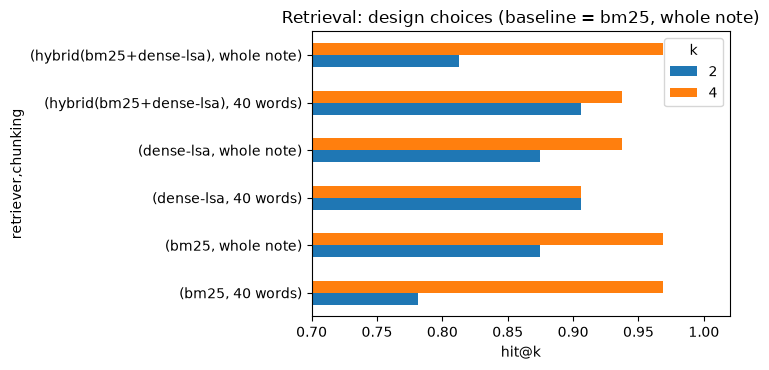

In [54]:
exp.to_csv(REPORTS_DIR / "retrieval_experiment.csv", index=False)
pv = exp.pivot_table(index=["retriever", "chunking"], columns="k", values="hit@k")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
pv.plot.barh(ax=ax); ax.set(xlabel="hit@k", xlim=(0.7, 1.02), title="Retrieval: design choices (baseline = bm25, whole note)")
savefig("07_retrieval_experiment.png")

**Reading the table.** All three retrievers find a gold note in the top 4 for essentially every answerable question, so with this small, clean knowledge base **the keyword baseline is hard to beat**; semantic or hybrid retrieval does not buy accuracy here. Smaller chunks do not help (the notes are already one idea each) and sometimes hurt at k = 2. The honest conclusion is that retrieval is *not* the bottleneck for this base; dense and hybrid retrieval become useful when questions are paraphrased more freely than these, or when the base grows (set `sentence-transformers` or an OpenAI key to use real embeddings). The default stays hybrid with whole-note chunks and k = 4 because it is never worse than BM25 here and is more robust to paraphrase in principle, which these questions cannot demonstrate.

**Optional: the same evaluation with Pinecone.** If `PINECONE_API_KEY` is set (and the `pinecone` SDK is installed) the notes are indexed in your Pinecone index and scored exactly like the local retrievers; otherwise the cell says so. `src/vectorstore.py` has not been run against Pinecone itself (it is tested with a fake client), so treat a first live run as a check of the adapter too.

In [55]:
from src.vectorstore import PineconeStore, PineconeRetriever
from src.evaluation import retrieval_eval
from src.rag import build_retriever
pstore = PineconeStore()
if pstore.available:
    try:
        print("indexed", pstore.index_notes(wait_s=10), "chunks into", pstore.settings.index_name)
        pr = PineconeRetriever(pstore, build_retriever("bm25"))
        rows = [{"retriever": "pinecone", "k": k, **retrieval_eval(pr, questions, k)} for k in (2, 4)]
        print("backend used for the last query:", pr.last_backend)
        print(pd.DataFrame(rows).round(3).to_string(index=False))
    except Exception as exc:
        print("Pinecone run failed:", type(exc).__name__, exc)
else:
    print("Pinecone not used:", pstore.status(), "(set PINECONE_API_KEY and pip install pinecone to run this cell)")

Pinecone run failed: VectorStoreUnavailable PineconeValueError: name contains invalid characters; must be lowercase alphanumeric and hyphens only


---
## 9. The final versions

What notebook 03 evaluates and the app loads. Everything is saved in `models/` (gitignored) and **rebuilt by `get_context()` if missing**, so a fresh clone works.

In [56]:
from src.functions import get_context
ctx = get_context(llm=llm, rebuild=True)
cfg = {"voltage_model": best_name, "retriever": ctx.retriever.name, "chunking": "whole note", "k": 4, "min_coverage": 0.34,
       "llm_model": llm.model, "embedding_backend": getattr(getattr(ctx.retriever, "dense", None), "backend", "n/a"),
       "surrogate_cv_mae_V": round(ctx.surrogate.cv_mae_, 4), "seed": SEED}
(MODELS_DIR / "pipeline_config.json").write_text(json.dumps(cfg, indent=1))
print(json.dumps(cfg, indent=1)); print(sorted(p.name for p in MODELS_DIR.iterdir()))

{
 "voltage_model": "Random Forest",
 "retriever": "hybrid(bm25+dense-openai)",
 "chunking": "whole note",
 "k": 4,
 "min_coverage": 0.34,
 "llm_model": "gpt-6-luna",
 "embedding_backend": "openai",
 "surrogate_cv_mae_V": 0.0268,
 "seed": 42
}
['.gitkeep', 'curve_corpus.csv', 'design_surrogate.joblib', 'index', 'pipeline_config.json', 'review_models.joblib', 'voltage_model.joblib', 'voltage_model_meta.json']


**Chosen and why.** Voltage: Random Forest (best CV, simple, no tuning needed). Retrieval: hybrid over whole notes with k = 4 (never worse than BM25 here, more robust to paraphrase in principle). Answers: grounded prompt with a relevance gate and citation check. Agent: tool-calling with an offline twin. These are evaluated **once** in notebook 03.